# Clasificación curricular automática de recursos educativos con una MLP
**DLY0100 – Deep Learning | Evaluación Parcial N.° 1**

Problema: clasificación supervisada **multiclase de etiqueta única** (4 categorías curriculares de Matemática) a partir de 22 variables numéricas. El dataset ya está limpio, por lo que el notebook se concentra en construir, entrenar, comparar y evaluar una Red Neuronal Multicapa (MLP) con TensorFlow/Keras.

## Índice (ordenado según la rúbrica)

| Sección | Contenido | Indicadores de la rúbrica |
|---|---|---|
| 1. Importaciones y configuración global | Librerías, semillas, tolerancia al ruido | – |
| 2. Carga y exploración de datos | Dimensiones, tipos, calidad, distribución del objetivo | 1 |
| 3. Preprocesamiento | Split estratificado y escalamiento sin fuga | 1 |
| 4. Modelo base: arquitectura, activación y pérdida | MLP 22 → 64 → 4, ReLU, softmax, crossentropy | 5, 7, 8 |
| 5. Entrenamiento y evaluación del modelo base | Épocas, lr, batch, Adam, métricas, referencia | 2, 11 |
| 6. Experimentos controlados (1 a 5) | Activación, pérdida, batch, learning rate, Dropout | 3, 5, 6, 7, 9, 10 |
| 7. Experimento 6: modelo base vs ajustado | Combina los valores más positivos de los experimentos 1 a 5 | 4, 10, 13 |
| 8. Evaluación final en test | Base vs ajustado, solo ahora se usa test | 11, 13 |
| 9. Interpretación y conclusiones | Lectura de resultados, limitaciones, mejoras | 12, 13 |

## Cómo está organizado el código
- **Una función hace una sola cosa:** o calcula, o arma una tabla, o dibuja un gráfico. Nunca dos de ellas a la vez.
- **Cada experimento sigue el mismo formato de 4 celdas:** (1) ejecutar, (2) tablas, (3) gráficos, (4) interpretación.
- **Un solo lugar para cambiar valores:** `CONFIG_BASE` (sección 5) y la llamada de cada experimento (sección 6).

---
## 1. Importaciones y configuración global

In [ ]:
import time
from dataclasses import dataclass

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, precision_recall_fscore_support,
                             classification_report, confusion_matrix)

# --- Parámetros globales (editables) ---
SEMILLA_GLOBAL = 42
SEMILLAS = (42, 43, 44)   # cada configuración se entrena con estas 3 semillas
TOL_RUIDO = 0.005         # diferencias menores a ~0,5 % se consideran dentro del ruido

tf.keras.utils.set_random_seed(SEMILLA_GLOBAL)
sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 160)
print("TensorFlow", tf.__version__)

TensorFlow 2.21.0


---
## 2. Carga y exploración de datos  *(indicador 1)*

Se carga el archivo desde Google Drive y se revisan **dimensiones, tipos de datos, nulos, duplicados y la distribución de la variable objetivo**. El dataset está depurado: no se realiza ETL, solo se verifica su calidad.

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
RUTA_CSV = "/content/drive/MyDrive/Deep Learning/Dataset_Clasificacion_Curricular_100000_LIMPIO.csv"
COLUMNA_OBJETIVO = "categoria_curricular"
NOMBRES_CLASES = ["Números y Op.", "Álgebra y Func.", "Geometría y Med.", "Datos y Prob."]


def cargar_datos(ruta):
    """Lee el CSV. No imprime ni dibuja nada."""
    return pd.read_csv(ruta)


def tabla_calidad_datos(df):
    """Dimensiones, nulos, duplicados y tipos de datos."""
    return pd.DataFrame({
        "filas": [df.shape[0]], "columnas": [df.shape[1]],
        "nulos": [int(df.isna().sum().sum())], "duplicados": [int(df.duplicated().sum())],
        "columnas float": [int((df.dtypes == "float64").sum())],
        "columnas int": [int((df.dtypes == "int64").sum())],
    }, index=["dataset"])


def tabla_distribucion_objetivo(df):
    """Registros y proporción de cada clase."""
    conteo = df[COLUMNA_OBJETIVO].value_counts().sort_index()
    return pd.DataFrame({"clase": NOMBRES_CLASES, "registros": conteo.values,
                         "proporción": (conteo / len(df)).round(4).values})


def tabla_descriptiva(df):
    """Estadísticos descriptivos de cada variable."""
    return df.describe().T.round(3)


def grafico_distribucion_objetivo(df):
    """Barras con la proporción de cada clase."""
    prop = df[COLUMNA_OBJETIVO].value_counts(normalize=True).sort_index()
    ax = prop.rename(dict(enumerate(NOMBRES_CLASES))).plot(kind="bar", figsize=(6, 3), rot=15)
    ax.set_ylabel("Proporción")
    ax.set_title("Distribución de la variable objetivo")
    plt.tight_layout()
    plt.show()

In [ ]:
df = cargar_datos(RUTA_CSV)

In [ ]:
display(tabla_calidad_datos(df))

,filas,columnas,nulos,duplicados,columnas float,columnas int
dataset,100000,23,0,0,15,8


In [ ]:
display(tabla_distribucion_objetivo(df))

,clase,registros,proporción
0,Números y Op.,30219,0.3022
1,Álgebra y Func.,26967,0.2697
2,Geometría y Med.,23065,0.2306
3,Datos y Prob.,19749,0.1975


In [ ]:
display(tabla_descriptiva(df))

,count,mean,std,min,25%,50%,75%,max
nivel_escolar,100000.0,8.496,2.290,5.000,6.000,8.000,10.000,12.000
duracion_estimada_min,100000.0,37.089,10.940,10.000,30.000,37.000,45.000,83.000
numero_paginas,100000.0,13.211,4.901,1.000,10.000,13.000,17.000,34.000
numero_items,100000.0,19.665,5.958,3.000,16.000,20.000,24.000,43.000
porcentaje_visual,100000.0,53.665,15.450,5.000,42.730,53.110,64.082,95.000
densidad_simbolos,100000.0,0.432,0.139,0.000,0.336,0.429,0.527,1.000
prop_operaciones_aritmeticas,100000.0,0.409,0.207,0.002,0.245,0.387,0.558,0.998
prop_fracciones_decimales,100000.0,0.382,0.199,0.001,0.225,0.359,0.523,0.974
prop_variables_algebraicas,100000.0,0.378,0.209,0.001,0.212,0.348,0.522,0.992
prop_ecuaciones,100000.0,0.360,0.201,0.001,0.199,0.331,0.498,0.977


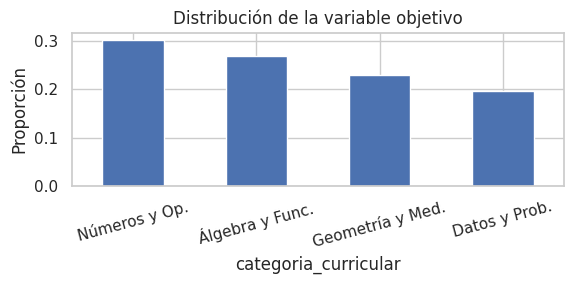

In [ ]:
grafico_distribucion_objetivo(df)

---
## 3. Preprocesamiento  *(indicador 1)*

El dataset ya está limpio; el preprocesamiento se limita a lo necesario para entrenar la red neuronal.

**Decisiones:**
- **Limpieza:** El dataset inicial está limpio. Al revisar su contenido con la función `display(tabla_calidad_datos(df))` comprobamos que carece de datos duplicados y nulos, lo que indica integridad y ausencia de redundancia en el dataset, por lo que decidimos no efectuar un procedimiento de limpieza extra.
- **Separación X / y:** las 22 variables predictoras (X) se separan de la variable objetivo `categoria_curricular` (y). No se crean variables nuevas.
- **División 70 % train / 15 % validación / 15 % test, estratificada** (`random_state=42`): las clases no están perfectamente balanceadas, y estratificar mantiene sus proporciones en los tres conjuntos.
- **Escalamiento con `StandardScaler` ajustado solo con train:** estandarizamos las variables, ya que tienen escalas muy distintas (minutos, páginas, proporciones entre 0 y 1), y aplicamos ajuste solo en train. Esto permite que validación y test no 'conozcan' el modelo estadístico de las variables por sí mismos, sino que se transformen acorde a train.
- **Uso de cada conjunto:** train para aprender; validación para comparar configuraciones y para early stopping; **test solo en la evaluación final** (sección 8).

In [ ]:
def dividir_datos(df, prop_val=0.15, prop_test=0.15, seed=SEMILLA_GLOBAL):
    """Split estratificado train / validación / test. Sin escalar."""
    X = df.drop(columns=COLUMNA_OBJETIVO)
    y = df[COLUMNA_OBJETIVO].values
    X_train, X_tmp, y_train, y_tmp = train_test_split(
        X, y, test_size=prop_val + prop_test, stratify=y, random_state=seed)
    X_val, X_test, y_val, y_test = train_test_split(
        X_tmp, y_tmp, test_size=prop_test / (prop_val + prop_test), stratify=y_tmp, random_state=seed)
    return X_train, X_val, X_test, y_train, y_val, y_test


def escalar_datos(X_train, X_val, X_test):
    """StandardScaler ajustado SOLO con train."""
    scaler = StandardScaler().fit(X_train)
    return scaler.transform(X_train), scaler.transform(X_val), scaler.transform(X_test), scaler


def tabla_control_split(conjuntos):
    """Tamaño, media/desv. de X y proporción de cada clase por conjunto."""
    filas = []
    for nombre, (X, y) in conjuntos.items():
        prop = np.bincount(y, minlength=len(NOMBRES_CLASES)) / len(y)
        filas.append({"conjunto": nombre, "filas": X.shape[0], "variables": X.shape[1],
                      "media X": X.mean(), "desv. X": X.std(),
                      **{f"clase {i}": p for i, p in enumerate(prop)}})
    return pd.DataFrame(filas).set_index("conjunto").round(4)

In [ ]:
X_train, X_val, X_test, y_train, y_val, y_test = dividir_datos(df)
X_train, X_val, X_test, scaler = escalar_datos(X_train, X_val, X_test)

CONJUNTOS = {"train": (X_train, y_train), "validación": (X_val, y_val), "test": (X_test, y_test)}
display(tabla_control_split(CONJUNTOS))

,filas,variables,media X,desv. X,clase 0,clase 1,clase 2,clase 3
conjunto,,,,,,,,
train,70000,22,-0.0000,1.0000,0.3022,0.2697,0.2307,0.1975
validación,15000,22,0.0034,0.9993,0.3022,0.2697,0.2306,0.1975
test,15000,22,0.0040,1.0011,0.3022,0.2697,0.2307,0.1975


---
## 4. Modelo base: arquitectura, activación y pérdida  *(indicadores 5, 7, 8)*

**Decisiones:**
- **Arquitectura 22 → 64 → 4 (una capa oculta):** hay 22 variables de entrada, 4 clases y 70.000 registros de entrenamiento. Una red pequeña basta para capturar relaciones no lineales sin riesgo alto de sobreajuste, y la consigna pide una arquitectura sencilla (1 o 2 capas ocultas).
- **Activación oculta ReLU:** barata de calcular, no se satura para valores positivos y suele entrenar rápido. Se compara con Tanh en el experimento 1.
- **Salida softmax con 4 neuronas:** las clases son mutuamente excluyentes (etiqueta única), así que se necesita una distribución de probabilidad que sume 1. Una sigmoide trataría cada clase de forma independiente (multietiqueta), lo que no corresponde aquí.
- **Pérdida `sparse_categorical_crossentropy`:** es la pérdida natural para softmax con etiquetas enteras (0–3), sin necesidad de one-hot. Se compara con MSE en el experimento 2.
- **Dropout 0.0 en el modelo base:** su efecto se evalúa como experimento aparte (experimento 5).

In [ ]:
PERDIDA_SPARSE = "sparse_categorical_crossentropy"
PERDIDA_MSE = "mse"

# --- Configuración del modelo base (editable) ---
CONFIG_MODELO = dict(
    neuronas=(64,),           # tupla: una capa oculta de 64. (64, 32) = dos capas ocultas
    activacion="relu",        # activación de las capas ocultas
    dropout=0.0,              # 0.0 = sin Dropout
    perdida=PERDIDA_SPARSE,   # PERDIDA_SPARSE o PERDIDA_MSE
)


def construir_modelo(cfg, n_entradas=None, n_clases=len(NOMBRES_CLASES)):
    """Construye y compila una MLP a partir de un diccionario de configuración."""
    n_entradas = n_entradas or X_train.shape[1]
    capas = [tf.keras.Input(shape=(n_entradas,))]
    for n in cfg["neuronas"]:
        capas.append(tf.keras.layers.Dense(n, activation=cfg["activacion"]))
        if cfg.get("dropout", 0.0) > 0:
            capas.append(tf.keras.layers.Dropout(cfg["dropout"]))
    capas.append(tf.keras.layers.Dense(n_clases, activation="softmax"))
    model = tf.keras.Sequential(capas)

    if cfg["perdida"] == PERDIDA_SPARSE:
        metrica = tf.keras.metrics.SparseCategoricalAccuracy(name="accuracy")
    else:                      # MSE usa etiquetas one-hot
        metrica = tf.keras.metrics.CategoricalAccuracy(name="accuracy")
    model.compile(optimizer=tf.keras.optimizers.Adam(cfg.get("lr", 1e-3)),
                  loss=cfg["perdida"], metrics=[metrica])
    return model

In [ ]:
construir_modelo(CONFIG_MODELO).summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 64)             │         1,472 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 4)              │           260 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,732 (6.77 KB)

 Trainable params: 1,732 (6.77 KB)

 Non-trainable params: 0 (0.00 B)

---
## 5. Entrenamiento y evaluación del modelo base  *(indicadores 2, 11)*

**Configuración de entrenamiento:**
- **Optimizador Adam:** ajusta la tasa de aprendizaje por parámetro, converge rápido y es estable con poca sintonía, por lo que es una opción adecuada para una MLP sin necesidad de comparar optimizadores.
- **Learning rate 1e-3** y **batch size 32:** valores dentro del rango recomendado (lr entre 0,0005 y 0,001; batch de 32 o 64).
- **Hasta 50 épocas con `EarlyStopping`** sobre `val_loss` (paciencia 5, `min_delta=1e-3`, `restore_best_weights=True`): el entrenamiento se detiene cuando la validación deja de mejorar y se conservan los pesos de la mejor época.
- **Varias semillas:** los experimentos se repiten con 3 semillas para medir la variabilidad y no sacar conclusiones de una sola corrida.

**Evaluación:** accuracy, precision, recall y F1. Precision, recall y F1 se informan en promedio **weighted** (ponderado por la cantidad de registros de cada clase), porque las clases no están perfectamente balanceadas. En esta sección el modelo base se evalúa solo en **train y validación**. Como referencia se entrena una regresión logística: si la MLP rinde parecido, el límite lo ponen los datos y no la arquitectura.

In [ ]:
# --- Configuración de entrenamiento (editable) ---
CONFIG_ENTRENAMIENTO = dict(
    lr=1e-3,          # learning rate de Adam
    batch=32,         # tamaño de batch
    epocas=50,        # máximo de épocas (EarlyStopping puede detener antes)
    paciencia=5,      # épocas sin mejora antes de detener
    min_delta=1e-3,   # mejora mínima de val_loss para contarla como mejora
)

CONFIG_BASE = {**CONFIG_MODELO, **CONFIG_ENTRENAMIENTO}


def tabla_config(cfg):
    """Configuración como tabla de dos columnas."""
    return pd.DataFrame({"valor": {k: str(v) for k, v in cfg.items()}})


display(tabla_config(CONFIG_BASE))

,valor
neuronas,"(64,)"
activacion,relu
dropout,0.0
perdida,sparse_categorical_crossentropy
lr,0.001
batch,32
epocas,50
paciencia,5
min_delta,0.001


In [ ]:
def preparar_etiquetas(cfg):
    """Etiquetas enteras para la pérdida sparse; one-hot para MSE (solo para entrenar)."""
    if cfg["perdida"] == PERDIDA_SPARSE:
        return y_train, y_val
    n = len(NOMBRES_CLASES)
    return tf.keras.utils.to_categorical(y_train, n), tf.keras.utils.to_categorical(y_val, n)


def entrenar(cfg, semilla=SEMILLA_GLOBAL, verbose=0):
    """Entrena un modelo NUEVO. Devuelve (modelo, historia como dict, segundos)."""
    tf.keras.backend.clear_session()
    tf.keras.utils.set_random_seed(semilla)
    model = construir_modelo(cfg)
    y_tr, y_va = preparar_etiquetas(cfg)
    early_stop = tf.keras.callbacks.EarlyStopping(
        monitor="val_loss", min_delta=cfg["min_delta"], patience=cfg["paciencia"],
        restore_best_weights=True)
    t0 = time.time()
    history = model.fit(X_train, y_tr, validation_data=(X_val, y_va),
                        epochs=cfg["epocas"], batch_size=cfg["batch"],
                        callbacks=[early_stop], verbose=verbose)
    return model, history.history, time.time() - t0


def predecir(model, X):
    """Clases predichas (argmax de la salida softmax)."""
    return model.predict(X, verbose=0).argmax(axis=1)


def metricas(y_real, y_pred):
    """Accuracy y precision / recall / F1 en promedio weighted."""
    p, r, f1, _ = precision_recall_fscore_support(y_real, y_pred, average="weighted", zero_division=0)
    return {"accuracy": accuracy_score(y_real, y_pred), "precision": p, "recall": r, "f1": f1}


def evaluar(model, X, y):
    """Métricas de un modelo sobre un conjunto."""
    return metricas(y, predecir(model, X))

In [ ]:
def tabla_metricas_conjuntos(predictor, conjuntos):
    """Métricas por conjunto. `predictor` es una función X -> clases predichas."""
    return pd.DataFrame({n: metricas(y, predictor(X)) for n, (X, y) in conjuntos.items()}).T.round(4)


def tabla_reporte_clases(model, X, y):
    """Precision / recall / F1 por clase."""
    rep = classification_report(y, predecir(model, X), target_names=NOMBRES_CLASES,
                                output_dict=True, zero_division=0)
    return pd.DataFrame(rep).T.round(4)


def grafico_curvas_entrenamiento(historia, titulo=""):
    """Pérdida y accuracy de train vs validación (historia = dict de Keras)."""
    fig, ax = plt.subplots(1, 2, figsize=(9, 3.2))
    for a, clave, nombre in [(ax[0], "loss", "Pérdida"), (ax[1], "accuracy", "Accuracy")]:
        a.plot(historia[clave], label="train")
        a.plot(historia["val_" + clave], label="validación")
        a.set_title(f"{nombre} {titulo}")
        a.set_xlabel("época")
        a.legend()
    plt.tight_layout()
    plt.show()


def grafico_matriz_confusion(model, X, y, titulo=""):
    """Matriz de confusión."""
    plt.figure(figsize=(5, 4))
    sns.heatmap(confusion_matrix(y, predecir(model, X)), annot=True, fmt="d", cmap="Blues",
                cbar=False, xticklabels=NOMBRES_CLASES, yticklabels=NOMBRES_CLASES)
    plt.xlabel("Predicho")
    plt.ylabel("Real")
    plt.title(f"Matriz de confusión {titulo}")
    plt.tight_layout()
    plt.show()

In [ ]:
modelo_base, hist_base, t_base = entrenar(CONFIG_BASE, semilla=SEMILLA_GLOBAL)
print(f"Épocas ejecutadas: {len(hist_base['loss'])} | tiempo: {t_base:.1f} s")

ref = LogisticRegression(max_iter=1000).fit(X_train, y_train)     # referencia
conjuntos_dev = {"train": CONJUNTOS["train"], "validación": CONJUNTOS["validación"]}

print("\nMLP base")
display(tabla_metricas_conjuntos(lambda X: predecir(modelo_base, X), conjuntos_dev))
print("Regresión logística (referencia)")
display(tabla_metricas_conjuntos(ref.predict, conjuntos_dev))
print("MLP base · por clase (validación)")
display(tabla_reporte_clases(modelo_base, X_val, y_val))

Épocas ejecutadas: 7 | tiempo: 37.5 s

MLP base


,accuracy,precision,recall,f1
train,0.9140,0.9141,0.9140,0.9140
validación,0.9127,0.9128,0.9127,0.9127


Regresión logística (referencia)


,accuracy,precision,recall,f1
train,0.9137,0.9137,0.9137,0.9137
validación,0.9153,0.9153,0.9153,0.9152


MLP base · por clase (validación)


,precision,recall,f1-score,support
Números y Op.,0.9053,0.9091,0.9072,4533.0000
Álgebra y Func.,0.9105,0.9234,0.9169,4045.0000
Geometría y Med.,0.9104,0.9078,0.9091,3459.0000
Datos y Prob.,0.9303,0.9096,0.9198,2963.0000
accuracy,0.9127,0.9127,0.9127,0.9127
macro avg,0.9141,0.9125,0.9132,15000.0000
weighted avg,0.9128,0.9127,0.9127,15000.0000


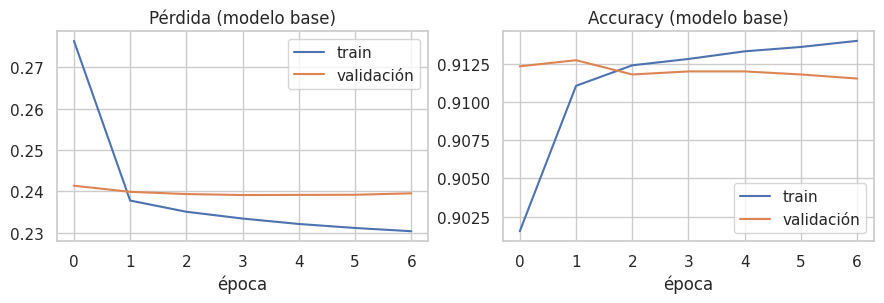

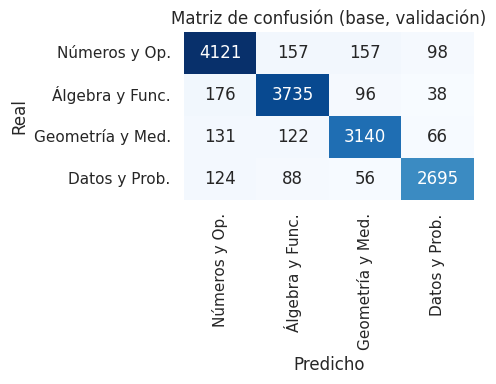

In [ ]:
grafico_curvas_entrenamiento(hist_base, "(modelo base)")
grafico_matriz_confusion(modelo_base, X_val, y_val, "(base, validación)")

**Interpretación del modelo base**
- Se aprecia una diferencia de 0.13 puntos porcentuales entre el accuracy de entrenamiento y el accuracy de validación; hay un rendimiento consistente en el modelo. Sin embargo, en comparación a una regresión logística nuestro modelo rinde ligeramente peor. La complejidad del modelo no nos otorga necesariamente meyor precisión.
Además, las métricas están razonablemente equilibradas a través de las clases. Se alcanza la mayor sensibilidad y precisión en la clase Datos y Probabilidad, y la menor sensibilidad en la clase más numerosa del dataset, Números y Operaciones. Debido a la naturaleza del datset, especulamos que esto se debe a que la clase más abundante tiene mayor superpocisión en contenidos con el resto de clases, lo que dificulta al modelo clasificar adecuadamente.

---
## 6. Experimentos controlados  *(indicadores 3, 5, 6, 7, 9, 10)*

En cada experimento se cambia **un solo parámetro** respecto del modelo base; todo lo demás queda fijo (mismo split, mismo `EarlyStopping`, mismas semillas). Cada configuración se entrena con 3 semillas y se reporta **media ± desviación estándar**.

| Experimento | Parámetro que cambia | Qué se mantiene fijo |
|---|---|---|
| 1. Activación | `activacion`: ReLU vs Tanh | Arquitectura, pérdida, batch y learning rate |
| 2. Error / pérdida | `perdida`: Crossentropy vs MSE | Arquitectura y parámetros de entrenamiento |
| 3. Batch | `batch`: 32 vs 64 | Todos los demás parámetros |
| 4. Learning rate | `lr`: 0,001 vs 0,0005 | Todos los demás parámetros |
| 5. Regularización | `dropout`: sin Dropout vs con Dropout | Arquitectura y parámetros restantes |

**Cómo leer las diferencias:** con ~15.000 registros de validación, el error estándar del accuracy es de ≈ 0,25 %. Una diferencia de F1 menor a ~0,5 % (`TOL_RUIDO`) se marca **dentro del ruido** y no permite afirmar que una configuración sea mejor. La brecha de accuracy (train − validación) indica sobreajuste cuando crece.

**Nota sobre MSE:** se entrena con etiquetas one-hot, pero las métricas se calculan siempre con las etiquetas enteras. Su `val_loss` tiene otra escala que la de Crossentropy, por eso las curvas y comparaciones usan accuracy y F1.

### 6.0 Infraestructura de los experimentos
Funciones reutilizables, agrupadas por tarea. Esta celda solo define funciones; no entrena nada.

In [ ]:
# ───── Datos del experimento ─────
@dataclass
class Resultado:
    nombre: str
    configs: dict            # etiqueta -> configuración
    runs: pd.DataFrame       # una fila por (configuración, semilla), métricas en validación
    historias: dict          # etiqueta -> historia (primera semilla)
    modelos: dict            # etiqueta -> lista de modelos entrenados (uno por semilla)
    parametro: str = None    # solo en experimentos de un parámetro (1 a 5)
    valor_base: object = None
    valor_alt: object = None


ABREVIATURAS = {PERDIDA_SPARSE: "crossentropy", PERDIDA_MSE: "MSE"}

def etiqueta(valor):
    """Texto corto para mostrar un valor de parámetro."""
    return ABREVIATURAS.get(valor, str(valor))

def variar(cfg, parametro, valor):
    """Copia de `cfg` cambiando SOLO `parametro`."""
    return {**cfg, parametro: valor}


# ───── Ejecución (entrena y mide; no muestra nada) ─────
def medir_corrida(nombre_cfg, semilla, model, historia, tiempo):
    """Una corrida = una fila: métricas en validación, brecha, épocas y tiempo."""
    val = evaluar(model, X_val, y_val)
    acc_train = evaluar(model, X_train, y_train)["accuracy"]
    return {"config": nombre_cfg, "semilla": semilla, **val,
            "brecha": acc_train - val["accuracy"],
            "mejor_epoca": int(np.argmin(historia["val_loss"])) + 1,
            "epocas": len(historia["val_loss"]), "tiempo_s": tiempo}


def correr_configuraciones(nombre, configs, semillas=SEMILLAS):
    """Entrena cada configuración con cada semilla."""
    filas, historias, modelos = [], {}, {}
    for nombre_cfg, cfg in configs.items():
        modelos[nombre_cfg] = []
        for s in semillas:
            model, historia, t = entrenar(cfg, s)
            filas.append(medir_corrida(nombre_cfg, s, model, historia, t))
            modelos[nombre_cfg].append(model)
            historias.setdefault(nombre_cfg, historia)
        print(f"OK  {nombre} | {nombre_cfg}")
    return Resultado(nombre, configs, pd.DataFrame(filas), historias, modelos)


def correr_experimento(nombre, parametro, valor_alt, cfg_base=None, semillas=SEMILLAS):
    """Compara el modelo base contra una versión que cambia SOLO `parametro`."""
    cfg_base = cfg_base or CONFIG_BASE
    valor_base = cfg_base[parametro]
    configs = {f"{etiqueta(valor_base)} (base)": cfg_base,
               etiqueta(valor_alt): variar(cfg_base, parametro, valor_alt)}
    res = correr_configuraciones(nombre, configs, semillas)
    res.parametro, res.valor_base, res.valor_alt = parametro, valor_base, valor_alt
    return res


# ───── Cálculo de diferencias (solo números) ─────
def media_por_config(res, columnas):
    return res.runs.groupby("config", sort=False)[columnas].mean()

def delta_f1(res):
    """Diferencia de F1 medio: alternativa - base."""
    m = media_por_config(res, ["f1"])["f1"]
    return m.iloc[1] - m.iloc[0]

def leer_diferencia(delta, tol=TOL_RUIDO):
    if abs(delta) < tol:
        return "dentro del ruido"
    return "mejora" if delta > 0 else "empeora"

In [ ]:
# ───── Tablas (solo devuelven DataFrames) ─────
def _media_std(runs, columnas, nombres, decimales=4):
    g = runs.groupby("config", sort=False)[columnas]
    media, desv = g.mean(), g.std().fillna(0)
    out = pd.DataFrame(index=media.index)
    for c, n in zip(columnas, nombres):
        out[n] = [f"{m:.{decimales}f} ± {s:.{decimales}f}" for m, s in zip(media[c], desv[c])]
    return out


def tabla_metricas(res):
    """Accuracy, precision, recall y F1 en validación (media ± desv.)."""
    return _media_std(res.runs, ["accuracy", "precision", "recall", "f1"],
                      ["Accuracy", "Precision", "Recall", "F1"])


def tabla_entrenamiento(res):
    """Brecha train-val, mejor época, épocas y tiempo (media ± desv.)."""
    brecha = _media_std(res.runs, ["brecha"], ["Brecha acc (train − val)"])
    resto = _media_std(res.runs, ["mejor_epoca", "epocas", "tiempo_s"],
                       ["Mejor época", "Épocas", "Tiempo (s)"], decimales=1)
    return brecha.join(resto)


def tabla_diferencia(res):
    """Diferencia de cada configuración respecto de la primera (la base)."""
    media = media_por_config(res, ["accuracy", "f1", "brecha"])
    dif = (media - media.iloc[0]).round(4)
    dif.columns = ["Δ Accuracy", "Δ F1", "Δ Brecha"]
    dif["Lectura"] = ["referencia"] + [leer_diferencia(d) for d in dif["Δ F1"].iloc[1:]]
    return dif


def tabla_resumen_experimentos(resultados):
    """Una fila por experimento: F1 base, F1 alternativa, ΔF1 y lectura."""
    filas = []
    for r in resultados:
        m = media_por_config(r, ["f1"])["f1"]
        filas.append({"Experimento": r.nombre, "Base": etiqueta(r.valor_base),
                      "Alternativa": etiqueta(r.valor_alt), "F1 base": m.iloc[0],
                      "F1 alt.": m.iloc[1], "Δ F1": delta_f1(r), "Lectura": leer_diferencia(delta_f1(r))})
    return pd.DataFrame(filas).set_index("Experimento").round(4)


# ───── Gráficos (solo dibujan; un gráfico por función) ─────
def grafico_metricas(res, columnas=("accuracy", "f1")):
    """Barras de las métricas en validación (media ± desv.). Eje recortado."""
    g = res.runs.groupby("config", sort=False)[list(columnas)]
    media, desv = g.mean(), g.std().fillna(0)
    ax = media.plot(kind="bar", yerr=desv, capsize=3, figsize=(6, 3.2), rot=0, width=0.7)
    ax.set_ylim(media.values.min() - 0.01, media.values.max() + 0.01)
    ax.set_xlabel("")
    ax.set_title(f"{res.nombre} · validación (eje recortado)")
    plt.tight_layout()
    plt.show()


def grafico_curvas(res, clave="val_accuracy"):
    """Curva de validación por época de cada configuración (primera semilla)."""
    plt.figure(figsize=(6, 3.2))
    for nombre_cfg, h in res.historias.items():
        plt.plot(range(1, len(h[clave]) + 1), h[clave], label=nombre_cfg)
    plt.xlabel("época")
    plt.ylabel(clave)
    plt.title(f"{res.nombre} · {clave}")
    plt.legend()
    plt.tight_layout()
    plt.show()


def grafico_brecha(res):
    """Brecha de accuracy train − validación (media ± desv.)."""
    g = res.runs.groupby("config", sort=False)["brecha"]
    ax = g.mean().plot(kind="bar", yerr=g.std().fillna(0), capsize=3, figsize=(6, 3), rot=0, color="tab:gray")
    ax.set_xlabel("")
    ax.set_title(f"{res.nombre} · brecha de accuracy (train − val)")
    plt.tight_layout()
    plt.show()


def grafico_resumen_experimentos(resultados):
    """ΔF1 de cada experimento respecto del base; banda gris = ruido."""
    nombres = [r.nombre for r in resultados]
    deltas = [delta_f1(r) for r in resultados]
    plt.figure(figsize=(6, 0.6 * len(nombres) + 1.2))
    plt.axvspan(-TOL_RUIDO, TOL_RUIDO, color="lightgray", alpha=0.6, label="dentro del ruido")
    plt.barh(nombres, deltas, color=["tab:green" if d > 0 else "tab:red" for d in deltas])
    plt.axvline(0, color="black", linewidth=0.8)
    plt.gca().invert_yaxis()
    plt.xlabel("Δ F1 (alternativa − base)")
    plt.legend(loc="lower right", fontsize=8)
    plt.tight_layout()
    plt.show()

### 6.1 Experimento 1: Función de activación (ReLU vs Tanh)
- **Cambia:** `activacion`: relu → tanh
- **Se mantiene fijo:** arquitectura, pérdida, batch y learning rate

In [ ]:
exp1 = correr_experimento("Exp 1 · Activación", "activacion", "tanh")

OK  Exp 1 · Activación | relu (base)
OK  Exp 1 · Activación | tanh


In [ ]:
display(tabla_metricas(exp1))

,Accuracy,Precision,Recall,F1
config,,,,
relu (base),0.9134 ± 0.0006,0.9136 ± 0.0007,0.9134 ± 0.0006,0.9133 ± 0.0005
tanh,0.9132 ± 0.0008,0.9133 ± 0.0008,0.9132 ± 0.0008,0.9132 ± 0.0008


In [ ]:
display(tabla_entrenamiento(exp1))

,Brecha acc (train − val),Mejor época,Épocas,Tiempo (s)
config,,,,
relu (base),0.0003 ± 0.0009,4.3 ± 0.6,7.0 ± 0.0,37.0 ± 2.0
tanh,-0.0014 ± 0.0007,4.0 ± 0.0,6.0 ± 0.0,35.3 ± 3.7


In [ ]:
display(tabla_diferencia(exp1))

,Δ Accuracy,Δ F1,Δ Brecha,Lectura
config,,,,
relu (base),0.0000,0.0000,0.0000,referencia
tanh,-0.0002,-0.0002,-0.0016,dentro del ruido


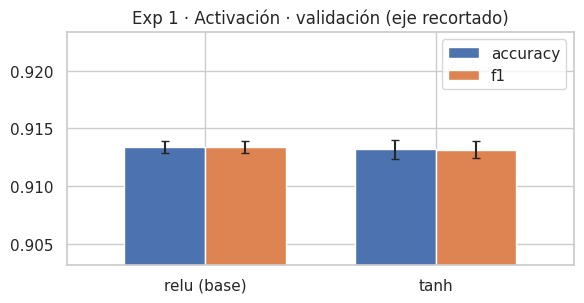

In [ ]:
grafico_metricas(exp1)

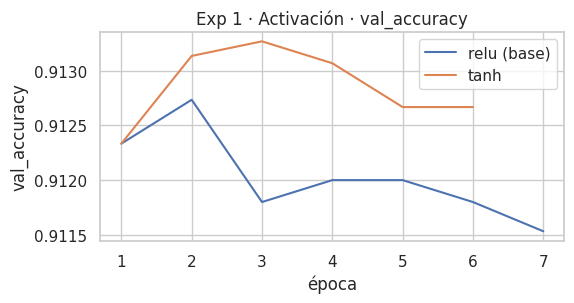

In [ ]:
grafico_curvas(exp1)

**Interpretación experimento 1:**

Se experimentó con la función ReLU y Tahn; comparadas, ambas tienen rendimientos equivalentes, aunque Tahn es ligeramente peor. Elegir cualquiera de las funciones no desembocará en una mejora estadísticamente significativa, por lo que se conservó ReLu.

### 6.2 Experimento 2: Función de pérdida (Crossentropy vs MSE)
- **Cambia:** `perdida`: sparse_categorical_crossentropy → mse
- **Se mantiene fijo:** arquitectura y parámetros de entrenamiento

In [ ]:
exp2 = correr_experimento("Exp 2 · Pérdida", "perdida", PERDIDA_MSE)

OK  Exp 2 · Pérdida | crossentropy (base)
OK  Exp 2 · Pérdida | MSE


In [ ]:
display(tabla_metricas(exp2))

,Accuracy,Precision,Recall,F1
config,,,,
crossentropy (base),0.9134 ± 0.0006,0.9136 ± 0.0007,0.9134 ± 0.0006,0.9133 ± 0.0005
MSE,0.9123 ± 0.0002,0.9125 ± 0.0002,0.9123 ± 0.0002,0.9123 ± 0.0002


In [ ]:
display(tabla_entrenamiento(exp2))

,Brecha acc (train − val),Mejor época,Épocas,Tiempo (s)
config,,,,
crossentropy (base),0.0003 ± 0.0009,4.3 ± 0.6,7.0 ± 0.0,44.5 ± 8.2
MSE,0.0004 ± 0.0009,3.0 ± 1.0,6.0 ± 0.0,38.5 ± 1.4


In [ ]:
display(tabla_diferencia(exp2))

,Δ Accuracy,Δ F1,Δ Brecha,Lectura
config,,,,
crossentropy (base),0.000,0.0000,0.0000,referencia
MSE,-0.001,-0.0011,0.0001,dentro del ruido


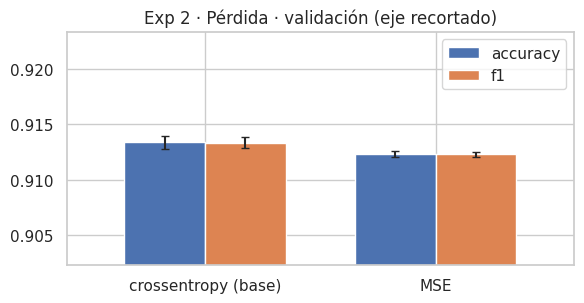

In [ ]:
grafico_metricas(exp2)

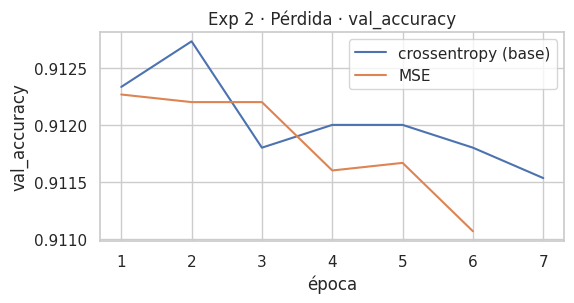

In [ ]:
grafico_curvas(exp2)

**Interpretación experimento 2:**

Categorical Cross-Entropy presenta un rendimiento ligeramente mejor, de 0.11 puntos porcentuales en comparación a MSE. Sin embargo, MSE encuentra su época ideal antes que Categorial Cross Entropy, lo que nos indica menos tiempo de ejecución. A pesar de eso, las diferencias son muy pequeñas, por lo que se conserva Categorical Cross-Entropy.


### 6.3 Experimento 3: Tamaño de batch (32 vs 64)
- **Cambia:** `batch`: 32 → 64
- **Se mantiene fijo:** todos los demás parámetros

In [ ]:
exp3 = correr_experimento("Exp 3 · Batch", "batch", 64)

OK  Exp 3 · Batch | 32 (base)
OK  Exp 3 · Batch | 64


In [ ]:
display(tabla_metricas(exp3))

,Accuracy,Precision,Recall,F1
config,,,,
32 (base),0.9134 ± 0.0006,0.9136 ± 0.0007,0.9134 ± 0.0006,0.9133 ± 0.0005
64,0.9131 ± 0.0009,0.9133 ± 0.0009,0.9131 ± 0.0009,0.9131 ± 0.0008


In [ ]:
display(tabla_entrenamiento(exp3))

,Brecha acc (train − val),Mejor época,Épocas,Tiempo (s)
config,,,,
32 (base),0.0003 ± 0.0009,4.3 ± 0.6,7.0 ± 0.0,41.1 ± 3.7
64,0.0012 ± 0.0007,6.0 ± 1.0,9.0 ± 0.0,26.9 ± 2.4


In [ ]:
display(tabla_diferencia(exp3))

,Δ Accuracy,Δ F1,Δ Brecha,Lectura
config,,,,
32 (base),0.0000,0.0000,0.0000,referencia
64,-0.0003,-0.0003,0.0009,dentro del ruido


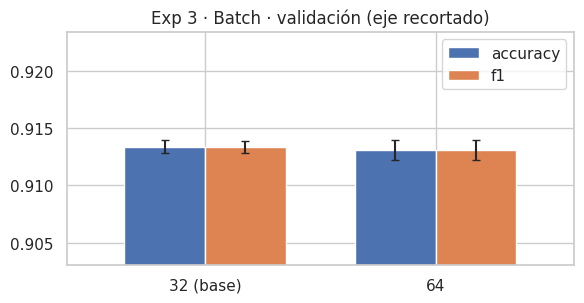

In [ ]:
grafico_metricas(exp3)

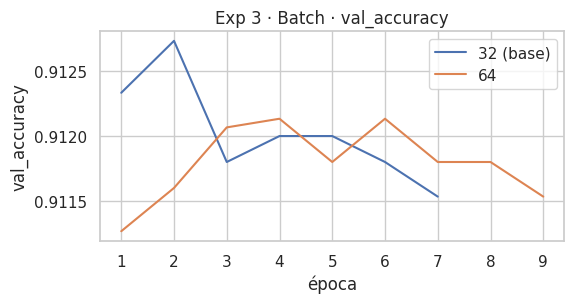

In [ ]:
grafico_curvas(exp3)

**Interpretación experimento 3:**

Las diferencias entre ambos tipos de batches, 64 versus 32, no superan el ruido estadistico. Además, el batch 32 presenta mayor velocidad que el batch 64. Lo más relevante es que el conjunto de validación permanece prácticamente plano en 64 batches, no refleja una mejora en comparación a los 32 batches.

### 6.4 Experimento 4: Learning rate (0,001 vs 0,0005)
- **Cambia:** `lr`: 0.001 → 0.0005
- **Se mantiene fijo:** todos los demás parámetros

In [ ]:
exp4 = correr_experimento("Exp 4 · Learning rate", "lr", 5e-4)

OK  Exp 4 · Learning rate | 0.001 (base)
OK  Exp 4 · Learning rate | 0.0005


In [ ]:
display(tabla_metricas(exp4))

,Accuracy,Precision,Recall,F1
config,,,,
0.001 (base),0.9134 ± 0.0006,0.9136 ± 0.0007,0.9134 ± 0.0006,0.9133 ± 0.0005
0.0005,0.9139 ± 0.0006,0.9140 ± 0.0005,0.9139 ± 0.0006,0.9139 ± 0.0005


In [ ]:
display(tabla_entrenamiento(exp4))

,Brecha acc (train − val),Mejor época,Épocas,Tiempo (s)
config,,,,
0.001 (base),0.0003 ± 0.0009,4.3 ± 0.6,7.0 ± 0.0,46.1 ± 10.1
0.0005,0.0004 ± 0.0003,8.0 ± 1.0,9.7 ± 1.2,70.2 ± 13.2


In [ ]:
display(tabla_diferencia(exp4))

,Δ Accuracy,Δ F1,Δ Brecha,Lectura
config,,,,
0.001 (base),0.0000,0.0000,0.0000,referencia
0.0005,0.0005,0.0005,0.0002,dentro del ruido


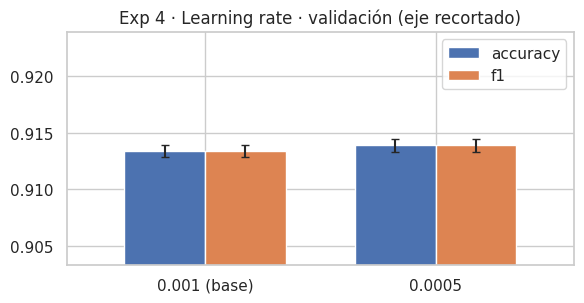

In [ ]:
grafico_metricas(exp4)

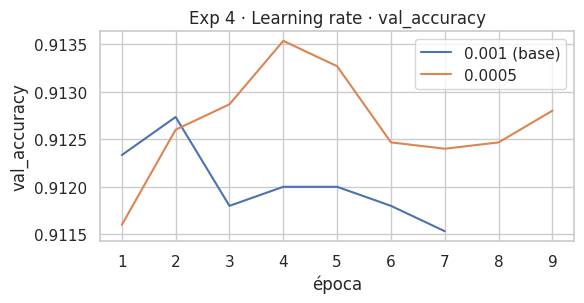

In [ ]:
grafico_curvas(exp4)

**Interpretación experimento 4:**

Hay une ligera mejora al utilizar una taza de aprendizaje menor (0.0005), presentando una mayor sensibilidad y precisión en el modelo. A pesar de que no se aprecia una mejora por encima del ruido estadístico, seleccionamos una tasa de aprendizaje de 0.0005 y descartamos la tasa base de 0.001

### 6.5 Experimento 5: Regularización (sin Dropout vs con Dropout)
- **Cambia:** `dropout`: 0.0 → 0.2
- **Se mantiene fijo:** arquitectura y parámetros restantes

In [ ]:
exp5 = correr_experimento("Exp 5 · Dropout", "dropout", 0.2)

OK  Exp 5 · Dropout | 0.0 (base)
OK  Exp 5 · Dropout | 0.2


In [ ]:
display(tabla_metricas(exp5))

,Accuracy,Precision,Recall,F1
config,,,,
0.0 (base),0.9134 ± 0.0006,0.9136 ± 0.0007,0.9134 ± 0.0006,0.9133 ± 0.0005
0.2,0.9133 ± 0.0012,0.9135 ± 0.0013,0.9133 ± 0.0012,0.9133 ± 0.0012


In [ ]:
display(tabla_entrenamiento(exp5))

,Brecha acc (train − val),Mejor época,Épocas,Tiempo (s)
config,,,,
0.0 (base),0.0003 ± 0.0009,4.3 ± 0.6,7.0 ± 0.0,54.1 ± 15.2
0.2,0.0007 ± 0.0015,6.3 ± 1.5,9.3 ± 1.5,54.3 ± 11.9


In [ ]:
display(tabla_diferencia(exp5))

,Δ Accuracy,Δ F1,Δ Brecha,Lectura
config,,,,
0.0 (base),0.0,0.0,0.0000,referencia
0.2,-0.0,-0.0,0.0004,dentro del ruido


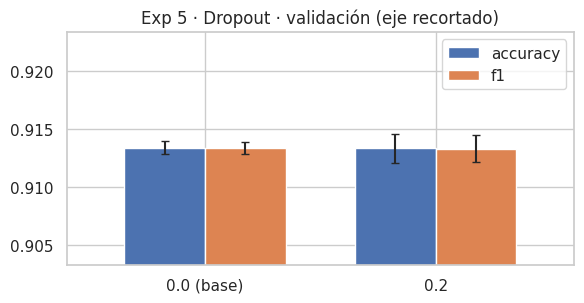

In [ ]:
grafico_metricas(exp5)

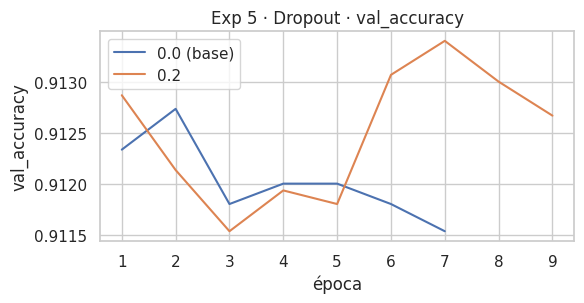

In [ ]:
grafico_curvas(exp5)

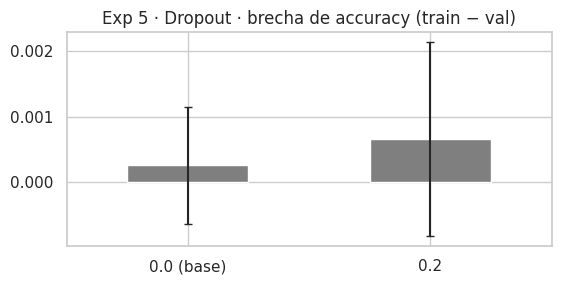

In [ ]:
grafico_brecha(exp5)

**Interpretación experimento 5:**

Se conserva un modelo sin DropOut, ya que las métricas empeoran ligeramente.

### 6.6 Resumen de los experimentos 1 a 5
Una sola vista para comparar cuánto movió cada parámetro el F1 respecto del modelo base.

In [ ]:
RESULTADOS_EXP = [exp1, exp2, exp3, exp4, exp5]

display(tabla_resumen_experimentos(RESULTADOS_EXP))

,Base,Alternativa,F1 base,F1 alt.,Δ F1,Lectura
Experimento,,,,,,
Exp 1 · Activación,relu,tanh,0.9133,0.9132,-0.0002,dentro del ruido
Exp 2 · Pérdida,crossentropy,MSE,0.9133,0.9123,-0.0011,dentro del ruido
Exp 3 · Batch,32,64,0.9133,0.9131,-0.0003,dentro del ruido
Exp 4 · Learning rate,0.001,0.0005,0.9133,0.9139,0.0005,dentro del ruido
Exp 5 · Dropout,0.0,0.2,0.9133,0.9133,-0.0000,dentro del ruido


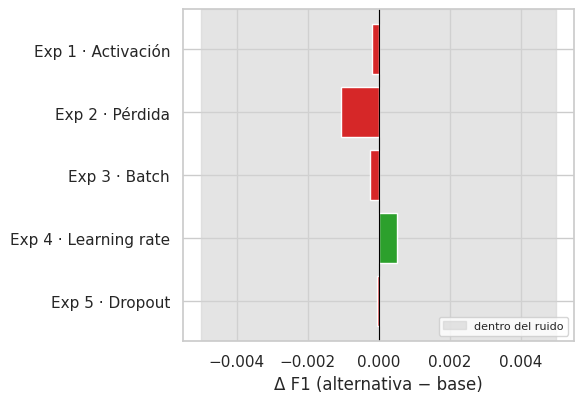

In [ ]:
grafico_resumen_experimentos(RESULTADOS_EXP)

**Interpretación resumen:**

Todos los ajustes no indican superación de relevancia estadística. La mayor brecha de sensibilidad entre modelo alternativo y base se obtiene al modificar la función de pérdida; MSE siento la descartada. Por otro lado, se observa una ligera mejora en el learning rate respecto del modelo base.
Se conservaron los parametros base, con excepción de tasa de aprendizaje.


---
## 7. Experimento 6: modelo base vs modelo ajustado  *(indicadores 4, 10, 13)*

El modelo ajustado toma, de cada experimento 1 a 5, el valor con **mayor F1 medio** en validación (`Δ F1 > 0`). Se compara contra el modelo base con las mismas métricas y semillas.

- `FORZAR`: para no adoptar (o forzar) un valor aunque el criterio automático diga otra cosa. Ejemplo: `{"dropout": 0.0}`.
- `AJUSTES_EXTRA`: para probar un cambio adicional sobre el ajustado (opcional). Ejemplo: `{"neuronas": (64, 32)}`.

In [ ]:
def elegir_ganadores(resultados, forzar=None):
    """Valor alternativo de cada experimento donde ΔF1 > 0. `forzar` tiene prioridad."""
    ganadores = {r.parametro: r.valor_alt for r in resultados if delta_f1(r) > 0}
    ganadores.update(forzar or {})
    return ganadores


def tabla_decision(resultados, ganadores):
    """Qué valor se adopta por parámetro y por qué."""
    filas = [{"Parámetro": r.parametro, "Base": etiqueta(r.valor_base), "Alternativa": etiqueta(r.valor_alt),
              "Δ F1": round(delta_f1(r), 4), "Lectura": leer_diferencia(delta_f1(r)),
              "Valor adoptado": etiqueta(ganadores.get(r.parametro, r.valor_base))} for r in resultados]
    return pd.DataFrame(filas).set_index("Parámetro")


def tabla_comparacion_configs(configs):
    """Configuraciones lado a lado; marca con ◄ los parámetros que difieren."""
    df = pd.DataFrame({k: {p: str(v) for p, v in cfg.items()} for k, cfg in configs.items()})
    df["cambia"] = np.where(df.nunique(axis=1) > 1, "◄", "")
    return df


# --- Opciones editables ---
FORZAR = {}
AJUSTES_EXTRA = {}

GANADORES = elegir_ganadores(RESULTADOS_EXP, FORZAR)
CONFIG_AJUSTADO = {**CONFIG_BASE, **GANADORES, **AJUSTES_EXTRA}

display(tabla_decision(RESULTADOS_EXP, GANADORES))
display(tabla_comparacion_configs({"base": CONFIG_BASE, "ajustado": CONFIG_AJUSTADO}))

,Base,Alternativa,Δ F1,Lectura,Valor adoptado
Parámetro,,,,,
activacion,relu,tanh,-0.0002,dentro del ruido,relu
perdida,crossentropy,MSE,-0.0011,dentro del ruido,crossentropy
batch,32,64,-0.0003,dentro del ruido,32
lr,0.001,0.0005,0.0005,dentro del ruido,0.0005
dropout,0.0,0.2,-0.0000,dentro del ruido,0.0


,base,ajustado,cambia
neuronas,"(64,)","(64,)",
activacion,relu,relu,
dropout,0.0,0.0,
perdida,sparse_categorical_crossentropy,sparse_categorical_crossentropy,
lr,0.001,0.0005,◄
batch,32,32,
epocas,50,50,
paciencia,5,5,
min_delta,0.001,0.001,


In [ ]:
exp6 = correr_configuraciones("Exp 6 · Base vs ajustado",
                              {"base": CONFIG_BASE, "ajustado": CONFIG_AJUSTADO})

OK  Exp 6 · Base vs ajustado | base
OK  Exp 6 · Base vs ajustado | ajustado


In [ ]:
display(tabla_metricas(exp6))

,Accuracy,Precision,Recall,F1
config,,,,
base,0.9134 ± 0.0006,0.9136 ± 0.0007,0.9134 ± 0.0006,0.9133 ± 0.0005
ajustado,0.9139 ± 0.0006,0.9140 ± 0.0005,0.9139 ± 0.0006,0.9139 ± 0.0005


In [ ]:
display(tabla_entrenamiento(exp6))

,Brecha acc (train − val),Mejor época,Épocas,Tiempo (s)
config,,,,
base,0.0003 ± 0.0009,4.3 ± 0.6,7.0 ± 0.0,40.3 ± 1.9
ajustado,0.0004 ± 0.0003,8.0 ± 1.0,9.7 ± 1.2,56.3 ± 5.0


In [ ]:
display(tabla_diferencia(exp6))

,Δ Accuracy,Δ F1,Δ Brecha,Lectura
config,,,,
base,0.0000,0.0000,0.0000,referencia
ajustado,0.0005,0.0005,0.0002,dentro del ruido


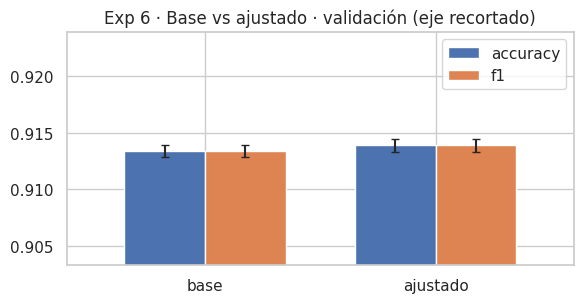

In [ ]:
grafico_metricas(exp6)

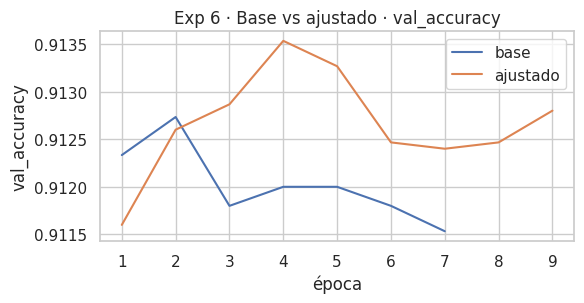

In [ ]:
grafico_curvas(exp6)

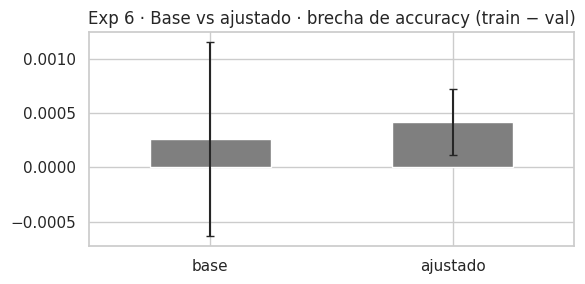

In [ ]:
grafico_brecha(exp6)

**Interpretación experimento 6:**

A través de todas las métricas, el modelo ajustado presenta un ligero mejor rendimiento, aunque con la ya mencionada limitante de no sobrepasar significancia estadística. El modelo ajustado también alcanza su mejor precisión más tarde, lo que podría suponer más tiempo de computo respecto al modelo base. Ninguna de las diferencias son significativas estadísticamente.

---
## 8. Evaluación final en test  *(indicadores 11, 13)*

El conjunto de test se usa **solo ahora**, con los mismos modelos ya entrenados del experimento 6 (no se reentrena nada). Se comparan base, ajustado y la regresión logística de referencia con las mismas métricas.

In [ ]:
def evaluar_test(res):
    """Métricas en test de cada modelo entrenado (una fila por configuración y semilla)."""
    filas = []
    for nombre_cfg, modelos in res.modelos.items():
        for semilla, m in zip(SEMILLAS, modelos):
            filas.append({"config": nombre_cfg, "semilla": semilla, **evaluar(m, X_test, y_test)})
    return pd.DataFrame(filas)


def tabla_test(runs_test):
    """Accuracy, precision, recall y F1 en test (media ± desv.)."""
    return _media_std(runs_test, ["accuracy", "precision", "recall", "f1"],
                      ["Accuracy", "Precision", "Recall", "F1"])


runs_test = evaluar_test(exp6)

print("MLP en test (media ± desv. entre semillas)")
display(tabla_test(runs_test))
print("Regresión logística (referencia)")
display(tabla_metricas_conjuntos(ref.predict, {"validación": CONJUNTOS["validación"], "test": CONJUNTOS["test"]}))

MLP en test (media ± desv. entre semillas)


,Accuracy,Precision,Recall,F1
config,,,,
base,0.9088 ± 0.0011,0.9089 ± 0.0011,0.9088 ± 0.0011,0.9087 ± 0.0012
ajustado,0.9091 ± 0.0010,0.9092 ± 0.0010,0.9091 ± 0.0010,0.9091 ± 0.0010


Regresión logística (referencia)


,accuracy,precision,recall,f1
validación,0.9153,0.9153,0.9153,0.9152
test,0.9109,0.9109,0.9109,0.9109


,precision,recall,f1-score,support
Números y Op.,0.8982,0.9073,0.9028,4533.0000
Álgebra y Func.,0.9102,0.9142,0.9122,4045.0000
Geometría y Med.,0.9174,0.9020,0.9096,3460.0000
Datos y Prob.,0.9205,0.9186,0.9196,2962.0000
accuracy,0.9102,0.9102,0.9102,0.9102
macro avg,0.9116,0.9106,0.9110,15000.0000
weighted avg,0.9103,0.9102,0.9102,15000.0000


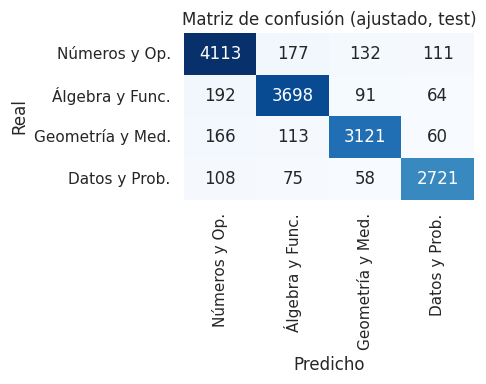

In [ ]:
modelo_ajustado = exp6.modelos["ajustado"][0]      # primera semilla

display(tabla_reporte_clases(modelo_ajustado, X_test, y_test))
grafico_matriz_confusion(modelo_ajustado, X_test, y_test, "(ajustado, test)")

---
## 9. Interpretación y conclusiones  *(indicadores 12, 13)*

Elegimos la configuración:


*   Arquitectura: 22 -> 64 -> 4
*   Acitvación: ReLU, con softmax de salida.
*   Pérdida: sparce categorical crossentropy
*   Regularización: sin Dropout.
*   Batch: 32
*   Learning rate: 0,0005 (alternativa al 0,001 de base)
*   Optimizador: Adam.


Através de las métricas, el modelo ajustado presenta mejor rendimiento, aunque sin sobrepasar significancia estadística. La regularización tuvo un efecto mínimo a la baja, con métricas de precisión y sensibilidad ligeramente peores.

La naturaleza del dataset alcanza un techo predictivo de 91%, y nuestro modelo no sobrepasó este umbral.La limitación más importante en este caso es que la complejidad del modelo no sobrepasó a una regresión logística, por lo que más profundidad y capacidad de cómputo no se traduce en un mejor rendimiento necesariamente.

Por otro lado, experimentaría más con la regularización, y la tasa de aprendizaje. A pesar de que nada ha sobrepasado el ruido estadistico de mejora, creo que pequeñas mejoras acumulativas podrían reflejar un rendimiento general más limpio.

